<a href="https://colab.research.google.com/github/nasif-raihan/GSU/blob/main/Module5_Lab_LogisticRegression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Module 5 — Logistic Regression (Lab)
**Computer Vision · Machine Learning for Vision**

Runs anywhere on scikit-learn built-in datasets. We cover binomial and multinomial logistic regression, the sigmoid and log-loss from scratch, and a from-scratch gradient-descent classifier with a decision boundary.

## 1. Binomial logistic regression (two classes)
Breast-cancer dataset: predict malignant vs. benign.

In [1]:
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

X, y = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=23)
clf = LogisticRegression(max_iter=10000, random_state=0).fit(X_train, y_train)
acc = accuracy_score(y_test, clf.predict(X_test)) * 100
print(f"Binomial logistic regression accuracy: {acc:.2f}%")

Binomial logistic regression accuracy: 96.49%


## 2. Multinomial logistic regression (many classes)
Digits dataset: classify handwritten digits 0–9.

In [2]:
from sklearn import datasets, linear_model, metrics
digits = datasets.load_digits()
X, y = digits.data, digits.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=1)
reg = linear_model.LogisticRegression(max_iter=10000, random_state=0).fit(X_train, y_train)
acc = metrics.accuracy_score(y_test, reg.predict(X_test)) * 100
print(f"Multinomial logistic regression accuracy: {acc:.2f}%")

Multinomial logistic regression accuracy: 96.66%


## 3. The sigmoid function
Maps any real score `z` to a probability in (0, 1).

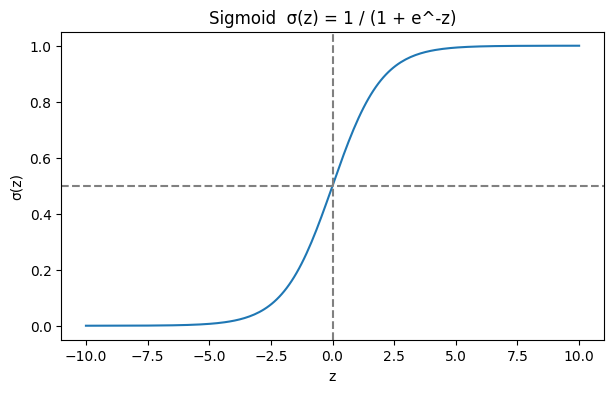

In [3]:
import numpy as np, matplotlib.pyplot as plt
def sigmoid(z): return 1 / (1 + np.exp(-z))     # note the MINUS in the exponent
z = np.linspace(-10, 10, 200)
plt.figure(figsize=(7,4)); plt.plot(z, sigmoid(z))
plt.axhline(0.5, ls="--", color="gray"); plt.axvline(0, ls="--", color="gray")
plt.title("Sigmoid  σ(z) = 1 / (1 + e^-z)"); plt.xlabel("z"); plt.ylabel("σ(z)"); plt.show()

## 4. Log loss (binary cross-entropy) from scratch
The cost logistic regression minimizes: penalizes confident-but-wrong predictions heavily.

In [4]:
def log_loss(y_true, y_pred, eps=1e-15):
    y_pred = np.clip(y_pred, eps, 1 - eps)
    return -np.mean(y_true*np.log(y_pred) + (1-y_true)*np.log(1-y_pred))

X_demo = np.array([0.2, 0.4, 0.6]); y_demo = np.array([0, 1, 1]); theta = 0.5
y_pred = sigmoid(X_demo * theta)
print("Predicted probabilities:", np.round(y_pred, 4))
print("Log loss:", round(log_loss(y_demo, y_pred), 4))

Predicted probabilities: [0.525  0.5498 0.5744]
Log loss: 0.6323


## 5. Logistic regression from scratch (gradient descent) + decision boundary
A one-neuron model: `z = w·x + b`, `p = σ(z)`. We learn `w, b` by gradient descent — the gradient of the log-loss is `Xᵀ(p − y)/m`.

from-scratch accuracy: 0.985 | weights: [1.386 0.377] bias: 4.647


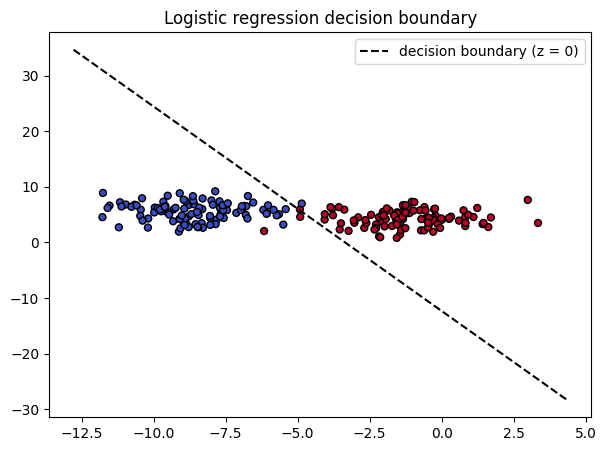

In [5]:
from sklearn.datasets import make_blobs
Xb, yb = make_blobs(n_samples=200, centers=2, n_features=2, cluster_std=1.6, random_state=7)

w = np.zeros(2); b = 0.0; lr = 0.1
for _ in range(2000):
    p = sigmoid(Xb @ w + b)
    grad_w = Xb.T @ (p - yb) / len(yb)
    grad_b = np.mean(p - yb)
    w -= lr * grad_w; b -= lr * grad_b

acc = ((sigmoid(Xb @ w + b) >= 0.5).astype(int) == yb).mean()
print("from-scratch accuracy:", round(acc, 4), "| weights:", np.round(w,3), "bias:", round(b,3))

# decision boundary: w·x + b = 0
xs = np.linspace(Xb[:,0].min()-1, Xb[:,0].max()+1, 100)
ys = -(w[0]*xs + b) / w[1]
plt.figure(figsize=(7,5))
plt.scatter(Xb[:,0], Xb[:,1], c=yb, cmap="coolwarm", edgecolor="k", s=25)
plt.plot(xs, ys, "k--", label="decision boundary (z = 0)")
plt.title("Logistic regression decision boundary"); plt.legend(); plt.show()

## 6. Interpreting coefficients
Each coefficient is the weight on one feature; its sign shows the direction of influence on the positive class.

In [6]:
data = load_breast_cancer()
print("A few coefficients (feature: weight):")
for name, coef in list(zip(data.feature_names, clf.coef_[0]))[:6]:
    direction = "increases" if coef > 0 else "decreases"
    print(f"  {name:22s} {coef:+.3f}  -> {direction} P(class 1)")

A few coefficients (feature: weight):
  mean radius            +1.129  -> increases P(class 1)
  mean texture           +0.170  -> increases P(class 1)
  mean perimeter         -0.279  -> decreases P(class 1)
  mean area              +0.020  -> increases P(class 1)
  mean smoothness        -0.162  -> decreases P(class 1)
  mean compactness       -0.212  -> decreases P(class 1)
